In [ ]:
import pandas as pd
import requests
import zipfile
import io

# Define the reliable URL for the zipped SMS dataset from UCI Machine Learning Repository
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip'

# Download the zip file content
response = requests.get(url)

# Check if the download was successful
if response.status_code == 200:
    # Open the zip file from memory
    with zipfile.ZipFile(io.BytesIO(response.content)) as z:
        # The dataset typically contains a .tsv file inside
        # Assuming the file is named 'SMSSpamCollection'
        with z.open('SMSSpamCollection') as f:
            # Load the TSV file into a pandas DataFrame
            # It is tab-separated and has no header by default
            df = pd.read_csv(f, sep='\t', header=None, encoding='latin-1')

    # Display the first 5 rows of the DataFrame
    print("Dataset loaded successfully:")
    print(df.head())
else:
    print(f"Failed to download the dataset. Status code: {response.status_code}")
    print("Please check the URL or your internet connection.")

Dataset loaded successfully:
      0                                                  1
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...


In [ ]:
import nltk
nltk.download('punkt')
nltk.download('punkt_tab') # Added to address LookupError

# Select a sample message from the DataFrame (e.g., the first message)
sample_message = df.iloc[0, 1] # Assuming message content is in the second column (index 1)

# Tokenize the sample message
tokenized_message = nltk.word_tokenize(sample_message)

# Print the original sample message and its tokenized output
print(f"Original Message: {sample_message}")
print(f"Tokenized Output: {tokenized_message}")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


Original Message: Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...
Tokenized Output: ['Go', 'until', 'jurong', 'point', ',', 'crazy', '..', 'Available', 'only', 'in', 'bugis', 'n', 'great', 'world', 'la', 'e', 'buffet', '...', 'Cine', 'there', 'got', 'amore', 'wat', '...']


In [ ]:
#Cleaning the Tokens: Preparing for Analysis

import string
from nltk.corpus import stopwords
nltk.download('stopwords')

def clean_text(text):
 # convert to lowercase
 text = text.lower()

 # remove punctuations
 text = ''.join([char for char in text if char not in string.punctuation])

 # Tokenized the text
 tokens = nltk.word_tokenize(text)

 # Remove Stop words
 stop_words = set (stopwords.words('english'))
 cleaned_tokens = [word for word in tokens if word not in stop_words]

 return cleaned_tokens

# Apply the clean_text function to the sample message
cleaned_tokens = clean_text(sample_message)

# Print the original and cleaned sample message
print(f"Original Message: {sample_message}")
print(f"Cleaned Tokens: {cleaned_tokens}")

Original Message: Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...
Cleaned Tokens: ['go', 'jurong', 'point', 'crazy', 'available', 'bugis', 'n', 'great', 'world', 'la', 'e', 'buffet', 'cine', 'got', 'amore', 'wat']


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [ ]:
import nltk
from nltk.stem import PorterStemmer, WordNetLemmatizer
nltk.download('wordnet')

# Initialize stemmer and lemmatizer
porter_stemmer = PorterStemmer()
wordnet_lemmatizer = WordNetLemmatizer()

# Apply stemming to the cleaned tokens
stemmmed_output = [porter_stemmer.stem(word) for word in cleaned_tokens]


# Apply lemmatization to the cleaned tokens
# For better lemmatization, part-of-speech (pos) tagging is often required,
# but for this basic demonstration, we'll use the default noun lemmatization.
lemmatized_output = [wordnet_lemmatizer.lemmatize(word) for word in cleaned_tokens]

# Print the outputs for comparison
print(f"Cleaned tokens: {cleaned_tokens}")
print(f"Stemmed output: {stemmmed_output}")
print(f"Lemmatized output: {lemmatized_output}")

[nltk_data] Downloading package wordnet to /root/nltk_data...


Cleaned tokens: ['go', 'jurong', 'point', 'crazy', 'available', 'bugis', 'n', 'great', 'world', 'la', 'e', 'buffet', 'cine', 'got', 'amore', 'wat']
Stemmed output: ['go', 'jurong', 'point', 'crazi', 'avail', 'bugi', 'n', 'great', 'world', 'la', 'e', 'buffet', 'cine', 'got', 'amor', 'wat']
Lemmatized output: ['go', 'jurong', 'point', 'crazy', 'available', 'bugis', 'n', 'great', 'world', 'la', 'e', 'buffet', 'cine', 'got', 'amore', 'wat']


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
import string
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
import nltk

nltk.download('wordnet')
nltk.download('stopwords')

# Initialize lemmatizer
wordnet_lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def preprocess_text(text):
  # Convert to lowercase
  text = str(text).lower()

  # Remove punctuation
  text_no_punct = ''.join([char for char in text if char not in string.punctuation])

  # Tokenize the text
  tokens = nltk.word_tokenize(text_no_punct)

  # Remove stop words and lemmatize
  processed_tokens = [wordnet_lemmatizer.lemmatize(word) for word in tokens if word not in stop_words]

  # Join tokens back into a single string
  return ''.join(processed_tokens)


# Apply the preprocessing function to the message content column (index 1)
df['processed_message'] = df.iloc[:,1].apply(preprocess_text)
# Create an instance of TfidfVectorizer
tfidf_vectorizer = TfidfVectorizer()

# Fit and transform a small subset of the processed messages
# Using the first 10 messages for demonstration
subset_processed_messages = df['processed_message'].head(10)
tfidf_matrix_subset = tfidf_vectorizer.fit_transform(subset_processed_messages)

# Get feature names (vocabulary)
feature_names = tfidf_vectorizer.get_feature_names_out()

# Display the resulting TF-IDF matrix as a DataFrame for better readability
tfidf_df = pd.DataFrame(tfidf_matrix_subset.toarray(), columns=feature_names)

print("\nProcessed Messages (first 10):\n")
for i, msg in enumerate(subset_processed_messages):
    print(f"Message {i+1}: {msg}")

print("\nTF-IDF Feature Names (Vocabulary):\n")
print(feature_names)

print("\nTF-IDF Matrix for the subset:\n")
print(tfidf_df)

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!



Processed Messages (first 10):

Message 1: gojurongpointcrazyavailablebugisngreatworldlaebuffetcinegotamorewat
Message 2: oklarjokingwifuoni
Message 3: freeentry2wklycompwinfacupfinaltkts21stmay2005textfa87121receiveentryquestionstdtxtratetcsapply08452810075over18s
Message 4: udunsayearlyhorucalreadysay
Message 5: nahdontthinkgousflifearoundthough
Message 6: freemsgheydarling3weekwordbackidlikefunstilltbokxxxstdchgssendâ£150rcv
Message 7: evenbrotherlikespeaktreatlikeaidpatent
Message 8: perrequestmellemelleoruminnaminungintenurunguvettamsetcallertunecallerpress9copyfriendcallertune
Message 9: winnervaluednetworkcustomerselectedreceiveaâ£900prizerewardclaimcall09061701461claimcodekl341valid12hour
Message 10: mobile11monthurentitledupdatelatestcolourmobilecamerafreecallmobileupdatecofree08002986030

TF-IDF Feature Names (Vocabulary):

['150rcv' '900prizerewardclaimcall09061701461claimcodekl341valid12hour'
 'evenbrotherlikespeaktreatlikeaidpatent'
 'freeentry2wklycompwinfacupfinaltkts21

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import TfidfVectorizer # Already imported, but good for clarity

# Define features (X) and labels (y)
x = df['processed_message']
y = df.iloc[:,0] #Frist vcolumn contains 'ham' or 'spam'

# Split the data into training and testing sets (80/20 split)
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)
print(f"Training data shape: {x_train.shape}")
print(f"Testing data shape: {x_test.shape}")
print(f"Training labels shape: {y_train.shape}")
print(f"Testing labels shape: {y_test.shape}")

# Re-initialize TfidfVectorizer
tfidf_vectorizer = TfidfVectorizer()

# Fit the vectorizer on the training data and transform both training and test data
X_train_tfidf = tfidf_vectorizer.fit_transform(x_train)
X_test_tfidf = tfidf_vectorizer.transform(x_test)

print(f"Shape of x_train_tfidf: {X_train_tfidf.shape}")
print(f"Shape of x_test_tfidf: {X_test_tfidf.shape}")

# Initialize a Multinomial Naive Bayes classifier
nb_classifier = MultinomialNB()

# Train the Naive Bayes classifier
nb_classifier.fit(X_train_tfidf, y_train)

# Make predictions on the test data
y_pred = nb_classifier.predict(X_test_tfidf)

print("Naive Bayes model trained and predictions made.")

Training data shape: (4457,)
Testing data shape: (1115,)
Training labels shape: (4457,)
Testing labels shape: (1115,)
Shape of x_train_tfidf: (4457, 4420)
Shape of x_test_tfidf: (1115, 4420)
Naive Bayes model trained and predictions made.


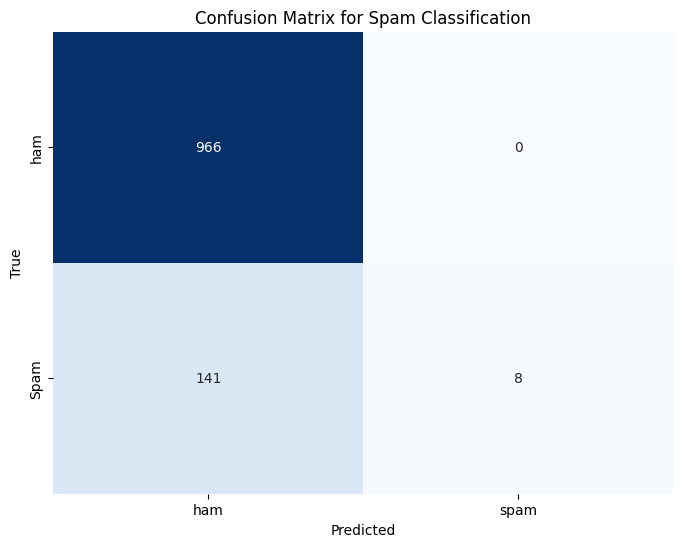

In [ ]:
# Visualize Confusion Matrix
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Compute the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Create a heatmap of the confusion matrix
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d' , cmap='Blues', cbar = False,
            xticklabels=['ham', 'spam'], yticklabels=['ham', 'Spam'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix for Spam Classification')
plt.show()

In [ ]:
import ipywidgets as widgets
from IPython.display import display

def predict_spam(message):
    # Preprocess the input message
    preprocessed_input = preprocess_text(message)

    # Transform the preprocessed message into a TF-IDF vector
    # tfidf_vectorizer was already fitted on training data
    input_tfidf = tfidf_vectorizer.transform([preprocessed_input])

   # Predict the label
    prediction = nb_classifier.predict(input_tfidf)[0]
    print(f"\nYour Message: '{message}' ")
    print(f"Predicted as: {prediction.upper()}")

# Create an interactive input widget (Textarea for multiline input)
text_input = widgets.Textarea(
    value='',
    placeholder = 'Enter your message here...',
    description = 'Message',
    disabled = False,
    layout = widgets.Layout(width='auto', height='100px')
)

# Create a button to trigger the prediction
button = widgets.Button(
    description='Predict',
    disabled = False,
    button_style='info',# 'success', 'info', 'warning', 'danger' or ''
    tooltip='Click to predict if the message is Spam or Safe',
    icon='check'
    )

# Link the button click event to the predict_message function
def on_button_clicked(b):
    predict_spam(text_input.value)

button.on_click(on_button_clicked)

  # Display the input widget and button
print("Enter a message to predict if it's SPAM or HAM")
display(text_input, button)

Enter a message to predict if it's SPAM or HAM


Textarea(value='', description='Message', layout=Layout(height='100px', width='auto'), placeholder='Enter your…

Button(button_style='info', description='Predict', icon='check', style=ButtonStyle(), tooltip='Click to predic…


Your Message: 'Hi How are you hope you are going will' 
Predicted as: HAM
